**PENDAHULUAN**

Dalam era perkembangan teknologi informasi yang pesat, pemanfaatan data untuk mengambil keputusan semakin menjadi fokus utama dalam berbagai bidang, termasuk di dalamnya dunia kesehatan. Penerapan teknik-teknik machine learning menjadi sebuah keharusan untuk meningkatkan presisi dan efisiensi dalam menganalisis data kesehatan, terutama dalam konteks prediksi penyakit.

Salah satu metode machine learning yang cukup populer dan sering digunakan adalah K-Nearest Neighbors (KNN). Metode ini memanfaatkan kumpulan data untuk membuat prediksi berdasarkan kesamaan atau kedekatan dengan data yang sudah ada sebelumnya. Dengan kata lain, KNN menggunakan informasi dari tetangga terdekat suatu data untuk memprediksi kelas atau nilai data tersebut.

Dalam konteks ini, fokus utama kita adalah pada prediksi penyakit stroke. Penggunaan metode KNN untuk prediksi penyakit stroke dapat memberikan gambaran yang lebih akurat berdasarkan data pasien yang telah tercatat sebelumnya.

**TUJUAN**

Untuk mengembangkan model prediksi penyakit stroke menggunakan metode KNN. Dengan memanfaatkan data historis pasien yang telah terkumpul, kita akan mencoba membangun model yang mampu mengidentifikasi faktor-faktor risiko dan pola yang berkaitan dengan kemungkinan seseorang mengalami stroke.

# **Import Library Yang Dibutuhkan**

In [1]:
#Loading libraries

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn import metrics

# **Dataset**

In [2]:
#Loading dataset

import pandas as pd
df = pd.read_csv('../input/prediksi-penyakit-stroke-knn/dataset-penyakit-stroke.csv')
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
2495,34383,Male,46.0,0,0,Yes,Private,Urban,88.23,25.8,Unknown,0
2496,8646,Female,54.0,0,0,Yes,Private,Rural,97.47,26.7,never smoked,0
2497,46653,Female,81.0,1,1,Yes,Private,Rural,59.28,28.1,never smoked,0
2498,1099,Female,15.0,0,0,No,children,Rural,101.15,22.2,Unknown,0


# **Analisis Data Eksploratif: Gambaran Informasi Dataset**

In [3]:
#Exploratory data analysis: Data Information

print(df.head())
print('\nDataset Shape :',df.shape,'\n')
df.info()

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  

Dataset Shape : (2500, 12) 

<class 'pandas.core.frame.

# **Analisis Jumlah Nilai Hilang (NaN) dalam DataFrame**

In [4]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  119
smoking_status         0
stroke                 0
dtype: int64

# **Penghapusan Nilai Hilang dan Analisis Pasca-Penghapusan**

In [5]:
df = df.dropna()

print(df.isnull().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


# **Konversi ke Tipe Data Integer**

In [6]:
df = df.replace('Male', 1)
df = df.replace('Female', 2)
df = df.replace('Other', 3)

df['gender'].astype('int')

0       1
2       1
3       2
4       2
5       1
       ..
2495    1
2496    2
2497    2
2498    2
2499    1
Name: gender, Length: 2381, dtype: int64

# **Pembersihan dan Konversi Data Kategorikal dalam DataFrame**

In [7]:
cleanup = {"ever_married" : {"Yes":0, "No":1},
          "Residence_type" :{"Urban":0, "Rural":1},
          "work_type" :{"Private":0, "Self-employed":1, "children" : 2, "Govt_job":3, "Never_worked":4},
          "smoking_status" :{"never smoked":0, "Unknown":1, "formerly smoked" : 2, "smokes":3}}

df = df.replace(cleanup)
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,0,0,0,228.69,36.6,2,1
2,31112,1,80.0,0,1,0,0,1,105.92,32.5,0,1
3,60182,2,49.0,0,0,0,0,0,171.23,34.4,3,1
4,1665,2,79.0,1,0,0,1,1,174.12,24.0,0,1
5,56669,1,81.0,0,0,0,0,0,186.21,29.0,2,1


# **Informasi Detail tentang Struktur DataFrame**

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2381 entries, 0 to 2499
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 2381 non-null   int64  
 1   gender             2381 non-null   int64  
 2   age                2381 non-null   float64
 3   hypertension       2381 non-null   int64  
 4   heart_disease      2381 non-null   int64  
 5   ever_married       2381 non-null   int64  
 6   work_type          2381 non-null   int64  
 7   Residence_type     2381 non-null   int64  
 8   avg_glucose_level  2381 non-null   float64
 9   bmi                2381 non-null   float64
 10  smoking_status     2381 non-null   int64  
 11  stroke             2381 non-null   int64  
dtypes: float64(3), int64(9)
memory usage: 241.8 KB


# **Pembagian Data : Data Latih dan Data Uji**

In [9]:
#Splitting into training and testing datasets

training_points = df.drop(columns=['id','stroke'])
training_labels = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
training_points, 
training_labels, 
test_size=0.3, 
random_state=4)

print(X_train)
print(y_train)
print(X_test)
print(y_test)

      gender   age  hypertension  heart_disease  ever_married  work_type  \
1222       1  10.0             0              0             1          2   
2072       2  63.0             0              0             0          3   
493        2  23.0             0              0             1          0   
1581       2  44.0             0              0             0          0   
319        2  29.0             0              0             1          0   
...      ...   ...           ...            ...           ...        ...   
501        2  60.0             0              0             0          0   
2026       1  37.0             0              0             0          1   
760        2  39.0             0              0             0          0   
211        2  51.0             0              0             0          3   
1209       1  37.0             0              0             0          0   

      Residence_type  avg_glucose_level   bmi  smoking_status  
1222               1   

# **Analisis Model K-Nearest Neighbors (n_neighbors=10)**

In [10]:
#kNN Classification model using different values of k 

classifier = KNeighborsClassifier(n_neighbors = 10)
classifier.fit(X_train, y_train)
guesses = classifier.predict(X_test)

print(guesses)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

# **Pelatihan Model KNN**

In [11]:
#Training model

classifier = KNeighborsClassifier(n_neighbors = 3)
classifier.fit(X_train, y_train)
guesses = classifier.predict(X_test)

print(guesses)

[0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 1
 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

# **Optimasi Nilai K pada K-Nearest Neighbors dengan Analisis Akurasi Pengujian**

[0.8475524475524475, 0.8993006993006993, 0.8769230769230769, 0.9006993006993007, 0.8993006993006993, 0.9062937062937063, 0.9006993006993007, 0.9118881118881119, 0.9076923076923077, 0.916083916083916, 0.9104895104895104, 0.9132867132867133, 0.9118881118881119, 0.9146853146853147, 0.916083916083916, 0.9146853146853147, 0.9118881118881119, 0.916083916083916, 0.9174825174825175, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916, 0.916083916083916]


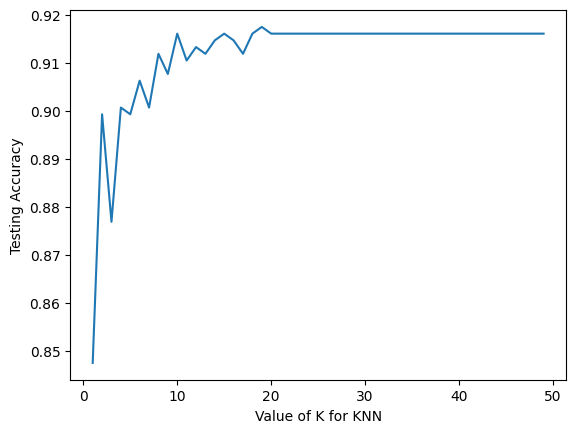

In [12]:
#Improving Accuracy: Tuning k parameter

k_range = range(1, 50)

accuracy_scores = []

for k in k_range:
    classifier = KNeighborsClassifier(n_neighbors = k)
    classifier.fit(X_train, y_train)
    guesses = classifier.predict(X_test)
    accuracy_scores.append(metrics.accuracy_score(y_test, guesses))
print(accuracy_scores)

plt.plot(k_range, accuracy_scores)
plt.xlabel('Value of K for KNN')
plt.ylabel('Testing Accuracy')
plt.show()

# **Analisis Dan Validasi Model**

In [13]:
## Metrik Evaluasi

# Displaying the classification report
print("Classification Report:")
print(classification_report(y_test,guesses))

# Confusion matrix
print(confusion_matrix(y_test, guesses), '\n')

#Checking out accuracy
print(metrics.accuracy_score(y_test, guesses))

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       655
           1       0.00      0.00      0.00        60

    accuracy                           0.92       715
   macro avg       0.46      0.50      0.48       715
weighted avg       0.84      0.92      0.88       715

[[655   0]
 [ 60   0]] 

0.916083916083916


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


# **Analisis Distribusi Kelas pada Kolom 'Stroke'**

In [14]:
# Mapping kelas stroke dan non-stroke 
mapping = {0: 'Tidak Stroke', 1: 'Stroke'}

# Print mapping
print(mapping, '\n') 

print(df['stroke'].value_counts())
print()
print(df['stroke'].value_counts()/np.float64(len(df)))

{0: 'Tidak Stroke', 1: 'Stroke'} 

stroke
0    2172
1     209
Name: count, dtype: int64

stroke
0    0.912222
1    0.087778
Name: count, dtype: float64


# **Visualisasi Data Hasil Prediksi**

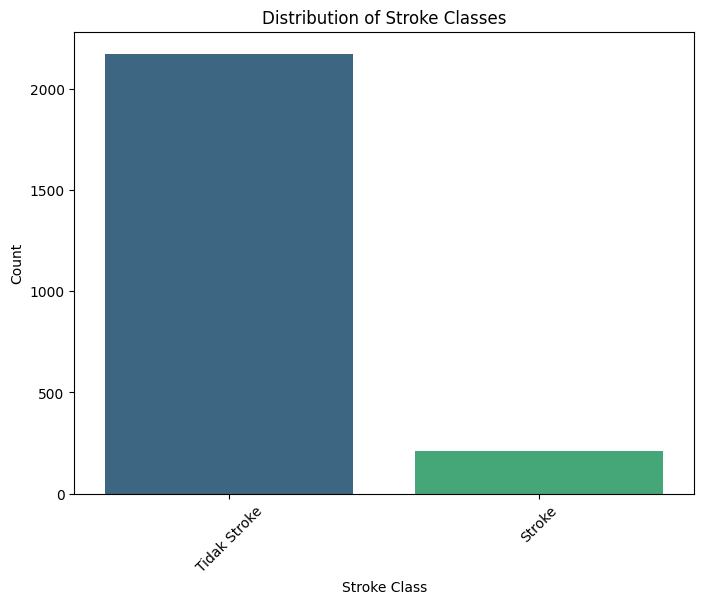

In [15]:
# Visualisasi distribusi kelas stroke dan non-stroke
plt.figure(figsize=(8, 6))
sns.countplot(x='stroke', data=df, palette='viridis')
plt.title('Distribution of Stroke Classes')
plt.xlabel('Stroke Class')
plt.ylabel('Count')

# Menambahkan label kelas pada sumbu x
plt.xticks([0, 1], ['Tidak Stroke', 'Stroke'], rotation=45)

# Menampilkan plot
plt.show()